# Initial EDA 03: Outlier Detection

**Data source:** StatsBomb Open Data (https://github.com/hudl/open-data). All event data in this notebook comes from StatsBomb.

![StatsBomb logo](images/statsbomb_logo.png)

This notebook looks for unusual shots in the analysis table we built in `initial_eda_02.ipynb` (the big-4 men's leagues, 2015/16). We want to answer three questions:

1. Are there any rows with impossible or broken values, like a shot taken from off the pitch or a distance that doesn't match the shot location?
2. Which shots are extreme on a single feature, like a shot from 80 coordinate units out?
3. Which shots look strange when you look at several features together, even if no single value is extreme?

We **flag** outliers here. We don't delete anything. At the end we save a file of flags so the team can decide, shot by shot or rule by rule, what to keep before modeling.

All distances are in StatsBomb coordinate units. The pitch is 120 by 80 units, the goal is centered at (120, 40), and the posts sit at y = 36 and y = 44.

In [1]:
# import libraries

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import RobustScaler

pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 160)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

RANDOM_STATE = 42

## Load Data

This notebook reads the table that `initial_eda_02.ipynb` saves at the end: `output/initial_eda_receipt_features.csv`. Run 02 first so that file exists. The path is relative to the repo folder, so it works on any of our computers as long as both notebooks sit in the same folder.

The 02 table is already cleaned. Penalties, the 7 direct corners, the 32 shots with no keeper in the freeze frame, and the 6 shots with a pass but no matching receipt are all gone, and `is_goal` is already built. So we don't filter anything here.

The `output` folder isn't in the GitHub repo. StatsBomb's terms don't allow us to share their data, so keep it that way.

In [2]:
# Load the analysis table saved by initial_eda_02

output_folder = Path.cwd() / 'output'
shots_analysis_df = pd.read_csv(output_folder / 'initial_eda_receipt_features.csv')

# Sort by shot id so results match on every computer

shots_analysis_df = shots_analysis_df.sort_values('id').reset_index(drop=True)

shots_analysis_df['is_goal'] = shots_analysis_df['is_goal'].astype(bool)
shots_analysis_df['goalkeeper_in_lane'] = shots_analysis_df['goalkeeper_in_lane'].astype(bool)

print(shots_analysis_df.shape)
print(f"Goals: {shots_analysis_df['is_goal'].sum():,} ({shots_analysis_df['is_goal'].mean():.1%} of shots)")

(37443, 40)
Goals: 3,553 (9.5% of shots)


## Sanity Checks

Before looking for "unusual" shots, we check for rows that are simply wrong. Each check below is a rule that a correct row should never break. A shot that breaks one of these is most likely a data problem, not a real event.

A few of the checks use the triangle between the shooter, the keeper and the center of the goal. We know all three sides of it (`shot_distance`, `goalkeeper_distance_to_shooter` and `goalkeeper_distance_from_goal`), and no side of a triangle can be longer than the other two added together. If one is, at least one of the distances is wrong.

In [3]:
# Recalculate distance and angle from x and y to make sure they match the saved columns

df = shots_analysis_df
dx = 120 - df['x']
dy = df['y'] - 40
calc_distance = np.sqrt(dx**2 + dy**2)
calc_angle = np.degrees(np.arctan2(8 * dx, dx**2 + dy**2 - 16))

# Triangle between shooter, keeper and goal center (small tolerance for rounding)

d_shot = df['shot_distance']
d_gk_goal = df['goalkeeper_distance_from_goal']
d_gk_shooter = df['goalkeeper_distance_to_shooter']
broken_triangle = (
    (d_shot > d_gk_goal + d_gk_shooter + 0.01)
    | (d_gk_goal > d_shot + d_gk_shooter + 0.01)
    | (d_gk_shooter > d_shot + d_gk_goal + 0.01)
)

# Receipt and shot that don't line up: the ball moved more than 10 units in under half a second
# between the pass being received and the shot. That's too fast for a dribble or a touch.

receipt_jump = (df['receipt_to_shot_seconds'] < 0.5) & (df['receipt_to_shot_displacement'] > 10)

checks = {
    'shot off the pitch': ~df['x'].between(0, 120) | ~df['y'].between(0, 80),
    "shot_distance doesn't match x, y": (calc_distance - d_shot).abs() > 0.01,
    "shot_angle doesn't match x, y": (calc_angle - df['shot_angle']).abs() > 0.01,
    'angle below 0 or above 180': ~df['shot_angle'].between(0, 180),
    'percent_of_goal_open outside 0 to 100': ~df['percent_of_goal_open'].between(0, 100),
    'more than 10 defenders or teammates in lane': (df['defenders_in_lane'] > 10) | (df['teammates_in_lane'] > 10),
    'keeper distances break the triangle rule': broken_triangle,
    'negative receipt-to-shot time or distance': (df['receipt_to_shot_seconds'] < 0) | (df['receipt_to_shot_displacement'] < 0),
    'moved over 10 units in under 0.5 seconds after receipt': receipt_jump,
    'duplicate shot id': df['id'].duplicated(keep=False),
    'keeper further from goal than the shooter': d_gk_goal > d_shot,
}

sanity = pd.DataFrame(checks)
sanity_summary = (
    sanity.sum().rename('shots_flagged').to_frame()
    .assign(percent=lambda d: (100 * d['shots_flagged'] / len(df)).round(2))
)
sanity_summary

,shots_flagged,percent
shot off the pitch,0,0.00
"shot_distance doesn't match x, y",0,0.00
"shot_angle doesn't match x, y",0,0.00
angle below 0 or above 180,0,0.00
percent_of_goal_open outside 0 to 100,0,0.00
more than 10 defenders or teammates in lane,0,0.00
keeper distances break the triangle rule,0,0.00
negative receipt-to-shot time or distance,0,0.00
moved over 10 units in under 0.5 seconds after receipt,38,0.10
duplicate shot id,0,0.00


In [4]:
# Look at a few of the flagged rows for each check

show_columns = ['match_id', 'player_name', 'minute', 'x', 'y', 'shot_distance', 'shot_angle',
                'goalkeeper_distance_from_goal', 'goalkeeper_distance_to_shooter',
                'receipt_to_shot_seconds', 'receipt_to_shot_displacement',
                'shot_type_name', 'shot_body_part_name', 'shot_outcome_name']

for name in sanity.columns:
    n = sanity[name].sum()
    if n == 0:
        continue
    print(f'\n=== {name} ({n} shots) ===')
    display(df.loc[sanity[name], show_columns].head(5))


=== moved over 10 units in under 0.5 seconds after receipt (38 shots) ===


,match_id,player_name,minute,x,y,shot_distance,shot_angle,goalkeeper_distance_from_goal,goalkeeper_distance_to_shooter,receipt_to_shot_seconds,receipt_to_shot_displacement,shot_type_name,shot_body_part_name,shot_outcome_name
103,3901148,Benjamin Jeannot,31,90.4,28.6,31.719395,13.450376,2.416609,29.307337,0.077,19.009471,Open Play,Left Foot,Off T
3379,3754237,Younes Kaboul,5,114.1,36.2,7.017834,54.837251,0.300000,7.184706,0.080,10.178900,Open Play,Head,Saved
3444,3825908,Gonzalo Escalante,89,89.1,39.1,30.913104,14.739661,1.702939,29.210957,0.154,12.209013,Open Play,Right Foot,Saved
4198,3754118,Adlène Guédioura,84,82.2,40.8,37.808465,12.075821,0.894427,37.019454,0.120,13.081667,Open Play,Right Foot,Blocked
4381,3825646,Cédric Bakambu,21,108.2,55.5,19.480503,14.558358,3.257299,16.443844,0.246,14.119844,Open Play,Right Foot,Saved



=== keeper further from goal than the shooter (272 shots) ===


,match_id,player_name,minute,x,y,shot_distance,shot_angle,goalkeeper_distance_from_goal,goalkeeper_distance_to_shooter,receipt_to_shot_seconds,receipt_to_shot_displacement,shot_type_name,shot_body_part_name,shot_outcome_name
206,3879803,Bruno Miguel Borges Fernandes,45,104.0,37.2,16.243152,27.314645,17.773013,22.095248,0.040,0.000000,Open Play,Right Foot,Goal
254,266056,Munir El Haddadi Mohamed,7,118.7,36.5,3.733631,101.203947,4.341659,7.702597,NaN,NaN,Open Play,Left Foot,Goal
267,3901252,Alexandre Lacazette,79,118.9,36.0,4.148494,82.170923,10.095544,12.060265,NaN,NaN,Open Play,Right Foot,Goal
421,3825620,Javier Guerra Rodríguez,90,115.0,38.6,5.192302,74.677030,5.420332,2.024846,NaN,NaN,Open Play,Right Foot,Blocked
463,3825682,Thomas Teye Partey,83,117.7,32.3,8.036168,20.744517,9.374433,9.078546,2.455,18.404347,Open Play,Left Foot,Off T


**What the sanity checks show:** see the summary at the end of the notebook. The short version is that the 02 table holds up well. Distance, angle and the keeper distances all agree with each other, and nothing is off the pitch.

Two checks do catch shots, but they point to real play, not bad data:

- **Keeper further from goal than the shooter.** This happens when the keeper has rushed out, been dribbled around, or is stranded up the pitch. About half of these shots score, so they matter a lot for the model.
- **Ball moved over 10 units in under half a second after the receipt.** Nobody dribbles that fast, so either the receipt spot or the shot spot is a little off. It's only a few dozen shots and their goal rate is normal, so they're worth a look but not worth dropping.

## Single-Feature Outliers (IQR and Robust Z-Score)

Next we look at each numeric feature on its own. We use two common rules:

- **IQR rule.** Find the middle 50% of values (from the 25th to the 75th percentile). The gap between them is the IQR. A value more than 1.5 IQRs past either edge is a mild outlier, and more than 3 IQRs is an extreme outlier.
- **Robust z-score.** A normal z-score uses the mean and standard deviation, but both get pulled around by the outliers we are trying to find. The robust version uses the median and the median absolute deviation (MAD) instead. A score above 3.5 is a common cutoff.

Some features are counts with only a few possible values (like `defenders_in_lane`). For those, the IQR can be 0 or 1, so the rule flags anything a little uncommon. For example, most shots have no teammates in the lane, so the IQR for `teammates_in_lane` is 0 and every shot with even one teammate in the lane gets flagged. We report these counts but leave them out of the combined flag later on.

The two receipt features are blank for shots that didn't come from a pass, so their counts only cover shots that have them.

In [5]:
numeric_features = [
    'x', 'y', 'shot_distance', 'shot_angle', 'percent_of_goal_open',
    'defenders_in_lane', 'teammates_in_lane',
    'goalkeeper_distance_from_goal', 'goalkeeper_distance_to_shooter',
    'receipt_to_shot_seconds', 'receipt_to_shot_displacement', 'minute',
]

def iqr_bounds(series, k):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

def robust_z(series):
    median = series.median()
    mad = (series - median).abs().median()
    if mad == 0:
        return pd.Series(np.nan, index=series.index)
    return 0.6745 * (series - median) / mad

rows = []
iqr_flags = pd.DataFrame(index=df.index)

for col in numeric_features:
    s = df[col]
    low, high = iqr_bounds(s.dropna(), 1.5)
    low3, high3 = iqr_bounds(s.dropna(), 3.0)
    z = robust_z(s)
    mild = (s < low) | (s > high)
    extreme = (s < low3) | (s > high3)
    iqr_flags[col] = extreme
    rows.append({
        'feature': col,
        'non_missing': s.notna().sum(),
        'median': round(s.median(), 2),
        'min': round(s.min(), 2),
        'max': round(s.max(), 2),
        'iqr_low_1.5': round(low, 2),
        'iqr_high_1.5': round(high, 2),
        'mild_outliers_1.5': int(mild.sum()),
        'extreme_outliers_3.0': int(extreme.sum()),
        'robust_z_over_3.5': int((z.abs() > 3.5).sum()),
        'goal_rate_extreme': round(df.loc[extreme, 'is_goal'].mean(), 3) if extreme.any() else np.nan,
    })

univariate_summary = pd.DataFrame(rows).set_index('feature')
univariate_summary

,non_missing,median,min,max,iqr_low_1.5,iqr_high_1.5,mild_outliers_1.5,extreme_outliers_3.0,robust_z_over_3.5,goal_rate_extreme
feature,,,,,,,,,,
x,37443,104.30,35.40,120.00,76.30,130.70,165,27,91,0.000
y,37443,39.70,1.50,78.80,9.95,69.55,62,0,1,NaN
shot_distance,37443,19.23,0.63,88.83,-7.85,46.37,164,27,94,0.000
shot_angle,37443,19.13,0.00,180.00,-8.02,52.91,2240,477,3102,0.564
percent_of_goal_open,37443,46.61,0.00,100.00,-36.54,128.89,0,0,0,NaN
defenders_in_lane,37443,1.00,0.00,8.00,-1.50,2.50,2289,199,8,0.070
teammates_in_lane,37443,0.00,0.00,5.00,0.00,0.00,5853,5853,0,0.046
goalkeeper_distance_from_goal,37443,3.05,0.10,70.38,-1.26,7.50,1856,698,1329,0.248
goalkeeper_distance_to_shooter,37443,15.48,0.36,74.03,-12.02,44.29,119,6,60,0.000


The last column shows how often the extreme shots went in. Compare it to the overall rate of about 9.5%. If the outliers score at a very different rate, they carry real signal, and dropping them would hide something the model should learn.

Notice that `shot_angle` and `goalkeeper_distance_from_goal` have lots of extreme values, and those shots score a lot. A huge angle just means the shooter was right on top of the goal, and a keeper far from goal often means an open net. These are the best chances in the game, not mistakes.

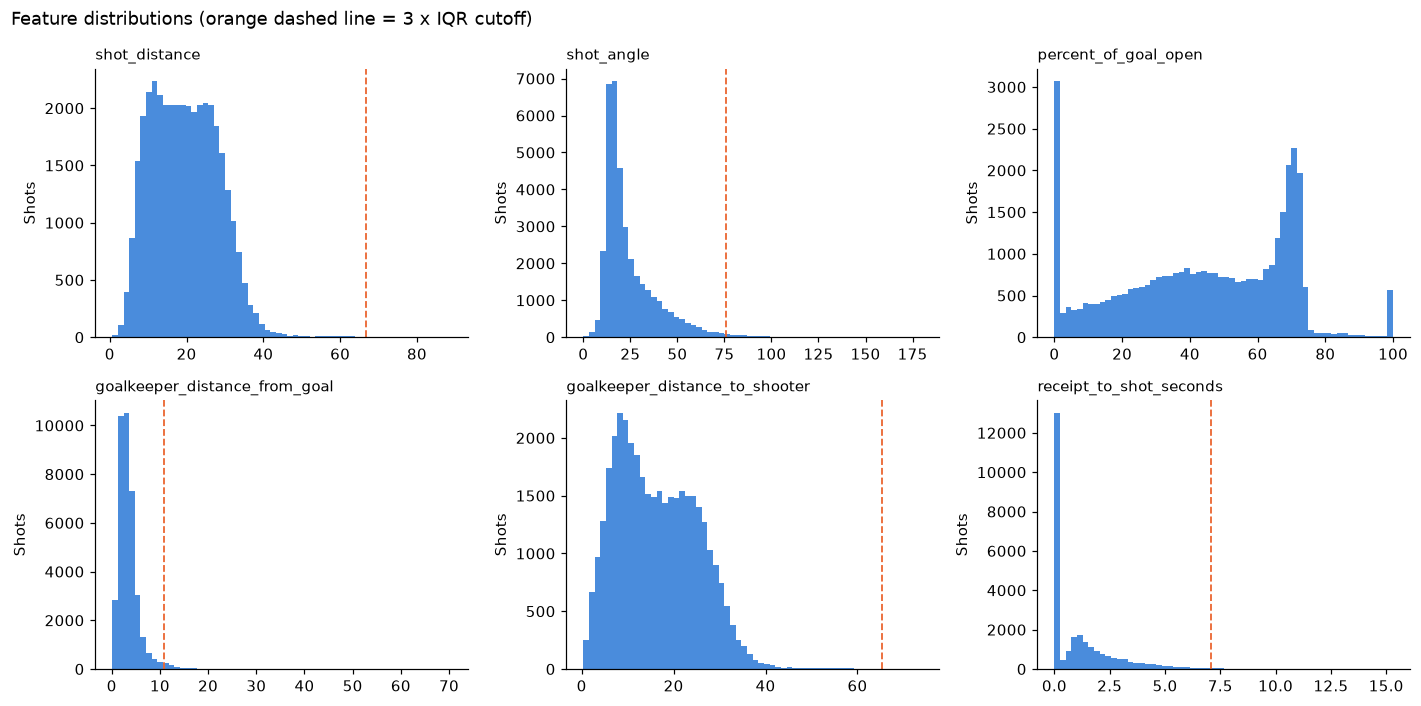

In [6]:
plot_features = ['shot_distance', 'shot_angle', 'percent_of_goal_open',
                 'goalkeeper_distance_from_goal', 'goalkeeper_distance_to_shooter', 'receipt_to_shot_seconds']

fig, axes = plt.subplots(2, 3, figsize=(13, 6.5))
for ax, col in zip(axes.ravel(), plot_features):
    data = df[col].dropna()
    low, high = iqr_bounds(data, 3.0)
    ax.hist(data, bins=60, color='#2a78d6', alpha=0.85)
    for b in (low, high):
        if data.min() <= b <= data.max():
            ax.axvline(b, color='#eb6834', ls='--', lw=1.2)
    ax.set_title(col, loc='left', fontsize=10)
    ax.set_ylabel('Shots')
fig.suptitle('Feature distributions (orange dashed line = 3 x IQR cutoff)', x=0.01, ha='left')
fig.tight_layout()
plt.show()

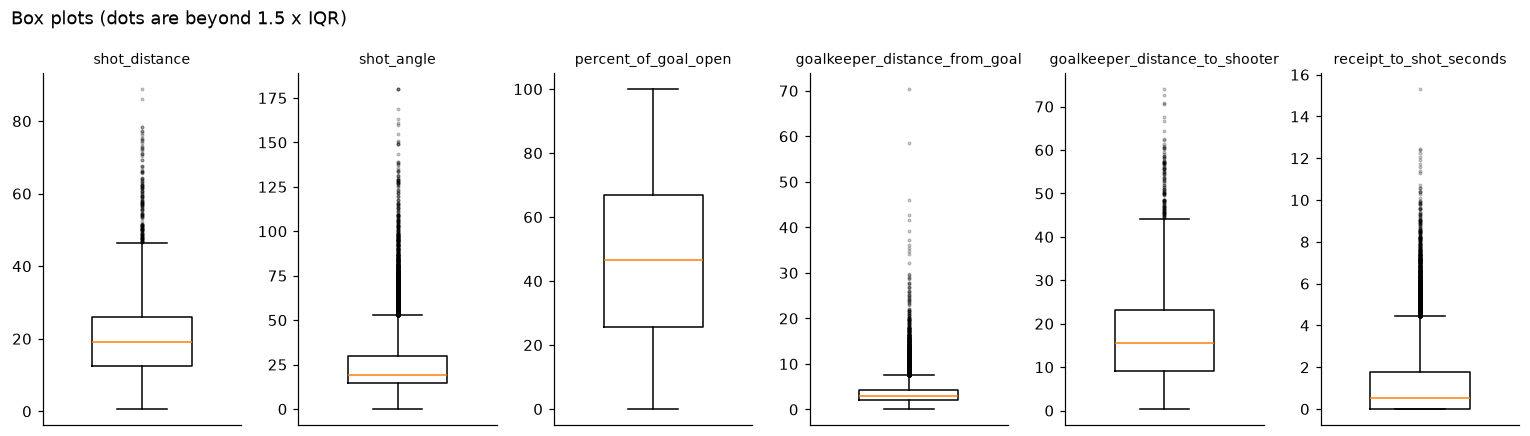

In [7]:
fig, axes = plt.subplots(1, len(plot_features), figsize=(14, 4))
for ax, col in zip(axes, plot_features):
    ax.boxplot(df[col].dropna(), whis=1.5, widths=0.5,
               flierprops=dict(marker='.', markersize=3, alpha=0.3))
    ax.set_title(col, fontsize=9)
    ax.set_xticks([])
fig.suptitle('Box plots (dots are beyond 1.5 x IQR)', x=0.01, ha='left')
fig.tight_layout()
plt.show()

### Long-Range Shots

Distance is the most important feature in any xG model, so it's worth a closer look. The shots past the 3 x IQR line are long-range efforts. They are rare and almost never score, but they are real shots. A model that never sees them would have no idea what to do with one.

In [8]:
_, distance_high = iqr_bounds(df['shot_distance'], 3.0)
long_shots = df[df['shot_distance'] > distance_high]

print(f'Shots beyond {distance_high:.1f} coordinate units: {len(long_shots)}, goals: {long_shots["is_goal"].sum()}')
long_shots.sort_values('shot_distance', ascending=False)[show_columns].head(10)

Shots beyond 66.7 coordinate units: 27, goals: 0


,match_id,player_name,minute,x,y,shot_distance,shot_angle,goalkeeper_distance_from_goal,goalkeeper_distance_to_shooter,receipt_to_shot_seconds,receipt_to_shot_displacement,shot_type_name,shot_body_part_name,shot_outcome_name
4231,3879746,Alex Nicolao Telles,55,38.7,4.2,88.833158,4.721173,23.544001,66.743164,NaN,NaN,Open Play,Left Foot,Wayward
9217,3754274,Xherdan Shaqiri,94,35.4,56.2,86.137100,5.223176,15.701274,74.030872,NaN,NaN,Open Play,Left Foot,Wayward
20250,3754054,Aleksandar Kolarov,9,43.7,21.6,78.487260,5.673429,11.260995,72.672003,1.240,7.531268,Open Play,Left Foot,Off T
33022,3901207,Atila Turan,93,46.8,11.9,78.408227,5.455280,58.545196,29.693939,NaN,NaN,Open Play,Left Foot,Wayward
34174,3879823,Gabriel Alejandro Paletta,78,43.1,31.5,77.368340,5.883619,6.964194,70.509574,NaN,NaN,Open Play,Right Foot,Wayward
9836,3879598,Fredy Alejandro Guarín Vásquez,7,43.3,30.7,77.261763,5.884554,6.675328,70.852664,3.759,13.640015,Open Play,Right Foot,Saved
16636,3901159,Zlatan Ibrahimović,7,50.1,71.7,76.752199,5.437294,16.514842,60.293947,1.354,4.560702,Open Play,Right Foot,Wayward
27764,3829469,Stephan El Shaarawy,38,50.3,9.5,76.081141,5.517573,21.883327,54.436201,0.076,9.079648,Open Play,Right Foot,Wayward
13247,3879661,Alejandro Darío Gómez,10,44.9,32.9,75.434873,6.043883,9.660228,67.487036,1.368,7.624303,Open Play,Right Foot,Wayward
26364,3879824,José Rodolfo Pires Ribeiro,46,51.3,9.8,75.044853,5.589620,19.014205,57.079331,1.640,10.269372,Open Play,Left Foot,Wayward


## Multivariate Outliers (Isolation Forest)

Some shots are only strange when you look at features together. A shot from 10 units out isn't unusual, and a keeper 10 units off the line isn't unheard of either. But a shot from 10 units out with the keeper standing behind the shooter is very unusual.

**Isolation Forest** finds these. It builds many random decision trees that keep splitting the data at random until each shot is alone. Normal shots sit in crowded areas, so they take many splits to isolate. Odd shots sit by themselves and get isolated in just a few splits. The fewer splits it takes, the higher the outlier score.

We set `contamination = 0.01`, which tells the model to flag the strangest 1% of shots (about 375). That number is a choice, not a fact about the data, so treat the flagged set as "worth a look" rather than "wrong."

We leave out `is_goal` and `shot_statsbomb_xg`, because we want shots that are odd in how they were taken, not in how they turned out. We also leave out the two receipt features, since they are blank for about a quarter of shots.

In [9]:
if_features = [
    'x', 'y', 'shot_distance', 'shot_angle', 'percent_of_goal_open',
    'defenders_in_lane', 'teammates_in_lane', 'goalkeeper_in_lane',
    'goalkeeper_distance_from_goal', 'goalkeeper_distance_to_shooter',
]

X = df[if_features].astype(float)
X_scaled = RobustScaler().fit_transform(X)

iso = IsolationForest(n_estimators=300, contamination=0.01, random_state=RANDOM_STATE)
iso.fit(X_scaled)

# score_samples is higher for normal shots, so flip the sign: higher = more unusual

df['iforest_score'] = -iso.score_samples(X_scaled)
df['iforest_outlier'] = iso.predict(X_scaled) == -1

n_out = df['iforest_outlier'].sum()
print(f'Isolation Forest flagged {n_out} shots ({n_out / len(df):.1%})')
print(f"Goal rate, flagged: {df.loc[df['iforest_outlier'], 'is_goal'].mean():.1%}")
print(f"Goal rate, not flagged: {df.loc[~df['iforest_outlier'], 'is_goal'].mean():.1%}")

Isolation Forest flagged 375 shots (1.0%)
Goal rate, flagged: 36.5%
Goal rate, not flagged: 9.2%


### Where Are the Flagged Shots?

The left plot shows where the shots were taken. The right plot shows how far each shot was from goal against how far the keeper was from goal. Shots above the dashed line had the keeper further from goal than the shooter. Gray dots are normal shots and orange dots are the ones Isolation Forest flagged.

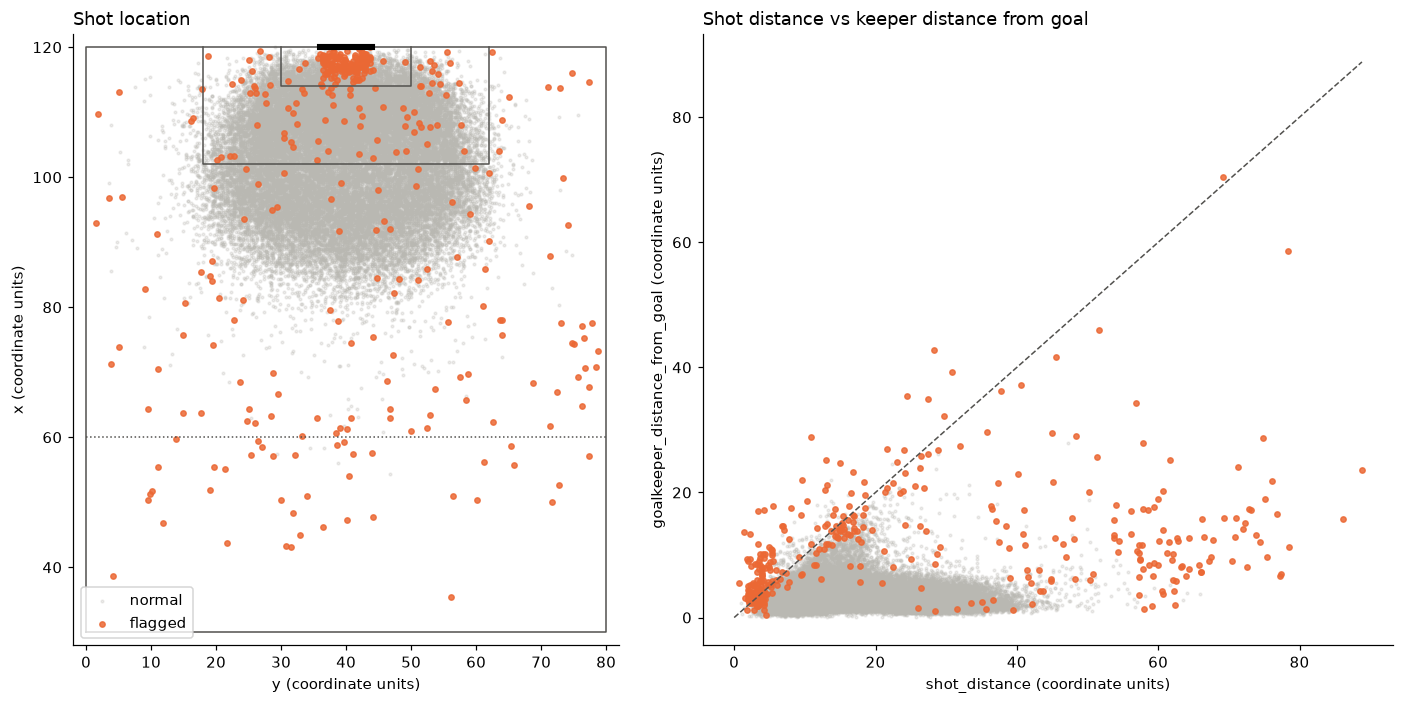

In [10]:
def draw_pitch(ax):
    ax.plot([0, 80, 80, 0, 0], [30, 30, 120, 120, 30], color='#52514e', lw=1)
    ax.plot([0, 80], [60, 60], color='#52514e', lw=1, ls=':')                # halfway line
    ax.plot([18, 18, 62, 62], [120, 102, 102, 120], color='#52514e', lw=1)  # penalty box
    ax.plot([30, 30, 50, 50], [120, 114, 114, 120], color='#52514e', lw=1)  # goal area
    ax.plot([36, 44], [120, 120], color='black', lw=4)                      # goal
    ax.set_xlim(-2, 82)
    ax.set_ylim(28, 122)
    ax.set_aspect('equal')
    ax.set_xlabel('y (coordinate units)')
    ax.set_ylabel('x (coordinate units)')

normal = df[~df['iforest_outlier']]
flagged = df[df['iforest_outlier']]

fig, axes = plt.subplots(1, 2, figsize=(13, 6.5), gridspec_kw={'width_ratios': [1, 1.2]})

draw_pitch(axes[0])
axes[0].scatter(normal['y'], normal['x'], s=3, color='#b9b8b2', alpha=0.25, label='normal')
axes[0].scatter(flagged['y'], flagged['x'], s=12, color='#eb6834', alpha=0.85, label='flagged')
axes[0].set_title('Shot location', loc='left')
axes[0].legend(loc='lower left')

axes[1].scatter(normal['shot_distance'], normal['goalkeeper_distance_from_goal'], s=3, color='#b9b8b2', alpha=0.25)
axes[1].scatter(flagged['shot_distance'], flagged['goalkeeper_distance_from_goal'], s=12, color='#eb6834', alpha=0.85)
lim = max(df['shot_distance'].max(), df['goalkeeper_distance_from_goal'].max())
axes[1].plot([0, lim], [0, lim], color='#52514e', ls='--', lw=1)
axes[1].set_xlabel('shot_distance (coordinate units)')
axes[1].set_ylabel('goalkeeper_distance_from_goal (coordinate units)')
axes[1].set_title('Shot distance vs keeper distance from goal', loc='left')

fig.tight_layout()
plt.show()

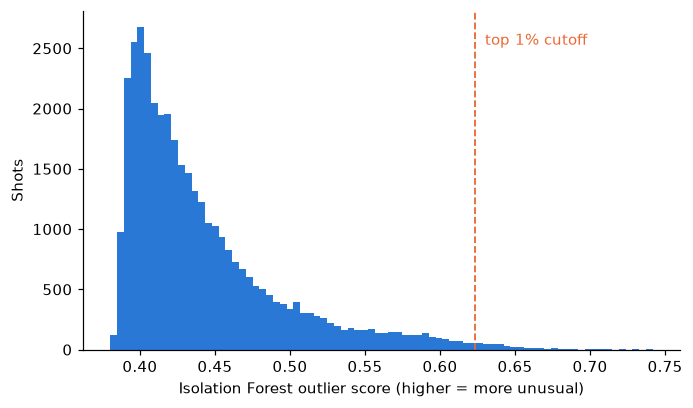

In [11]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(df['iforest_score'], bins=80, color='#2a78d6')
cut = df.loc[df['iforest_outlier'], 'iforest_score'].min()
ax.axvline(cut, color='#eb6834', ls='--', lw=1.2)
ax.text(cut, ax.get_ylim()[1] * 0.9, '  top 1% cutoff', color='#eb6834')
ax.set_xlabel('Isolation Forest outlier score (higher = more unusual)')
ax.set_ylabel('Shots')
plt.show()

### What Makes the Flagged Shots Different?

This table compares the median of each feature for flagged and normal shots. Big gaps tell us what the model is reacting to.

In [12]:
compare = pd.DataFrame({
    'normal_median': normal[if_features].astype(float).median(),
    'flagged_median': flagged[if_features].astype(float).median(),
})
compare['difference'] = compare['flagged_median'] - compare['normal_median']
compare.round(2)

,normal_median,flagged_median,difference
x,104.30,112.40,8.10
y,39.70,39.90,0.20
shot_distance,19.24,15.38,-3.87
shot_angle,19.13,18.21,-0.92
percent_of_goal_open,46.37,87.07,40.69
defenders_in_lane,1.00,0.00,-1.00
teammates_in_lane,0.00,0.00,0.00
goalkeeper_in_lane,1.00,0.00,-1.00
goalkeeper_distance_from_goal,3.04,9.23,6.19
goalkeeper_distance_to_shooter,15.51,7.91,-7.60


In [13]:
(df.sort_values('iforest_score', ascending=False)
   [['iforest_score'] + show_columns + ['percent_of_goal_open', 'defenders_in_lane', 'is_goal']]
   .head(15)
   .round(2))

,iforest_score,match_id,player_name,minute,x,y,shot_distance,shot_angle,goalkeeper_distance_from_goal,goalkeeper_distance_to_shooter,receipt_to_shot_seconds,receipt_to_shot_displacement,shot_type_name,shot_body_part_name,shot_outcome_name,percent_of_goal_open,defenders_in_lane,is_goal
4231,0.74,3879746,Alex Nicolao Telles,55,38.7,4.2,88.83,4.72,23.54,66.74,NaN,NaN,Open Play,Left Foot,Wayward,100.00,0,False
7927,0.74,3901263,François Kamano,78,57.1,77.4,73.18,5.38,17.12,56.97,3.59,29.43,Open Play,Right Foot,Saved,100.00,0,False
26364,0.74,3879824,José Rodolfo Pires Ribeiro,46,51.3,9.8,75.04,5.59,19.01,57.08,1.64,10.27,Open Play,Left Foot,Wayward,100.00,0,False
16792,0.73,267422,Juan Carlos Pérez López,18,51.9,19.0,71.26,6.14,24.03,48.34,NaN,NaN,Open Play,Left Foot,Off T,100.00,0,False
27764,0.73,3829469,Stephan El Shaarawy,38,50.3,9.5,76.08,5.52,21.88,54.44,0.08,9.08,Open Play,Right Foot,Wayward,4.55,1,False
9217,0.73,3754274,Xherdan Shaqiri,94,35.4,56.2,86.14,5.22,15.70,74.03,NaN,NaN,Open Play,Left Foot,Wayward,54.22,1,False
33022,0.72,3901207,Atila Turan,93,46.8,11.9,78.41,5.46,58.55,29.69,NaN,NaN,Open Play,Left Foot,Wayward,100.00,0,False
16418,0.72,3900615,Adrien Thomasson,75,77.1,76.3,56.20,6.23,17.02,39.48,NaN,NaN,Open Play,Right Foot,Off T,92.29,0,False
36031,0.72,3879720,José María Callejón Bueno,92,67.7,77.4,64.30,5.80,12.65,53.01,0.36,0.00,Open Play,Right Foot,Saved,100.00,0,False
6133,0.72,3753976,Bafétimbi Gomis,95,55.8,65.8,69.19,6.14,70.38,17.71,3.21,24.83,Open Play,Right Foot,Wayward,100.00,0,False


### Do the Flagged Shots Fall Into Groups?

Looking at the shot type, body part and outcome of flagged shots helps us tell real but rare situations (shots from far out, empty-net chances) apart from possible errors.

In [14]:
for col in ['shot_type_name', 'shot_body_part_name', 'shot_outcome_name', 'shot_open_goal', 'shot_one_on_one']:
    table = pd.crosstab(df[col], df['iforest_outlier'], normalize='columns').mul(100).round(1)
    table.columns = ['% of normal shots', '% of flagged shots']
    print(f'\n{col}')
    display(table)


shot_type_name


,% of normal shots,% of flagged shots
shot_type_name,,
Free Kick,4.7,3.5
Open Play,95.3,96.5



shot_body_part_name


,% of normal shots,% of flagged shots
shot_body_part_name,,
Head,16.4,13.1
Left Foot,31.6,31.5
Other,0.2,1.6
Right Foot,51.8,53.9



shot_outcome_name


,% of normal shots,% of flagged shots
shot_outcome_name,,
Blocked,25.4,11.2
Goal,9.2,36.5
Off T,33.8,27.7
Post,1.9,2.7
Saved,23.3,8.3
Saved Off Target,0.4,2.1
Saved to Post,0.3,0.0
Wayward,5.7,11.5



shot_open_goal


,% of normal shots,% of flagged shots
shot_open_goal,,
False,99.3,69.9
True,0.7,30.1



shot_one_on_one


,% of normal shots,% of flagged shots
shot_one_on_one,,
False,95.2,85.3
True,4.8,14.7


## League Comparison

Different leagues can have different styles of play. Some may be more defensive, while others play at a faster pace or take more shots. Comparing the four leagues can help us understand whether these differences affect shot quality and scoring rates.

In [15]:
# Compare playing style across leagues

league_check = df.groupby('competition_name').agg(
    shots=('id', 'count'),
    shots_per_match=('match_id', lambda m: len(m) / m.nunique()),
    goal_rate=('is_goal', 'mean'),
    median_distance=('shot_distance', 'median'),
    long_shot_share=('shot_distance', lambda d: (d > 25).mean()),
    avg_defenders_in_lane=('defenders_in_lane', 'mean'),
    median_goal_open=('percent_of_goal_open', 'median'),
    under_pressure=('under_pressure', 'mean'),
)
league_check.round(3)

,shots,shots_per_match,goal_rate,median_distance,long_shot_share,avg_defenders_in_lane,median_goal_open,under_pressure
competition_name,,,,,,,,
La Liga,9053,23.824,0.104,18.366,0.262,0.713,48.125,0.201
Ligue 1,8714,23.114,0.097,19.111,0.297,0.782,47.857,0.305
Premier League,9803,25.797,0.093,18.911,0.265,0.817,45.391,0.218
Serie A,9873,25.982,0.087,20.380,0.328,0.771,45.735,0.324


## Put It All Together

Here we build one table with every flag for every shot, then count how many shots each rule catches. The `n_flags` column counts how many of these four rules a shot breaks: a failed sanity check, extreme on a feature, Isolation Forest, and keeper further from goal than the shooter. A shot flagged by several rules at once is the best place to start a manual check.

In [16]:
flags = pd.DataFrame({'id': df['id'], 'match_id': df['match_id']})

# Checks that turned out to be real play get their own columns and don't count as data errors

real_play_checks = ['keeper further from goal than the shooter',
                    'moved over 10 units in under 0.5 seconds after receipt']
error_checks = [c for c in sanity.columns if c not in real_play_checks]

flags['sanity_error'] = sanity[error_checks].any(axis=1)
flags['keeper_ahead_of_shooter'] = sanity['keeper further from goal than the shooter']
flags['receipt_shot_mismatch'] = sanity['moved over 10 units in under 0.5 seconds after receipt']

for col in iqr_flags.columns:
    flags[f'iqr3_{col}'] = iqr_flags[col]
# Leave the count features out of "any": their IQR is 0 or 1, so the rule flags thousands of normal shots

count_features = ['defenders_in_lane', 'teammates_in_lane', 'minute']
flags['iqr3_any'] = iqr_flags.drop(columns=count_features).any(axis=1)

flags['iforest_score'] = df['iforest_score'].round(4)
flags['iforest_outlier'] = df['iforest_outlier']
flags['is_goal'] = df['is_goal']

flags['n_flags'] = flags[['sanity_error', 'iqr3_any', 'iforest_outlier', 'keeper_ahead_of_shooter']].sum(axis=1)

def summarize(mask, label):
    return {
        'rule': label,
        'shots_flagged': int(mask.sum()),
        'percent_of_shots': round(100 * mask.mean(), 2),
        'goal_rate_flagged': round(flags.loc[mask, 'is_goal'].mean(), 3) if mask.any() else np.nan,
    }

summary = pd.DataFrame([
    summarize(flags['sanity_error'], 'Sanity check failed (possible data error)'),
    summarize(flags['keeper_ahead_of_shooter'], 'Keeper further from goal than shooter (real play)'),
    summarize(flags['receipt_shot_mismatch'], "Receipt and shot spots don't line up (worth a look)"),
    summarize(flags['iqr3_any'], 'Extreme on at least one feature (3 x IQR)'),
    summarize(flags['iforest_outlier'], 'Isolation Forest top 1%'),
    summarize(flags['n_flags'] >= 2, 'Flagged by 2 or more rules'),
    summarize(pd.Series(True, index=flags.index), 'All shots (for comparison)'),
]).set_index('rule')
summary

,shots_flagged,percent_of_shots,goal_rate_flagged
rule,,,
Sanity check failed (possible data error),0,0.00,NaN
Keeper further from goal than shooter (real play),272,0.73,0.640
Receipt and shot spots don't line up (worth a look),38,0.10,0.079
Extreme on at least one feature (3 x IQR),1814,4.84,0.264
Isolation Forest top 1%,375,1.00,0.365
Flagged by 2 or more rules,365,0.97,0.471
All shots (for comparison),37443,100.00,0.095


In [17]:
# Save the flags next to the 02 output so other notebooks can join them on id

flags.to_csv(output_folder / 'initial_eda_03_outlier_flags.csv', index=False)
print('Files saved in the output folder')

Files saved in the output folder


## What We Found and What To Do Next

**The data has no real errors.** No shot is off the pitch, distance and angle match the coordinates, `percent_of_goal_open` stays between 0 and 100, the three keeper and shot distances always form a real triangle, and every shot id is unique. The 02 cleaning did its job.

**Two things are worth a look, but neither is a reason to drop shots:**
- 272 shots had the keeper further from goal than the shooter. That's real soccer (the keeper rushed out or got rounded), and 64% of these went in.
- 38 shots moved more than 10 units in under half a second between the receipt and the shot. One of the two spots is probably logged a little off, which matters for `receipt_to_shot_displacement`. Their goal rate is normal.

**Most single-feature outliers are real soccer.** They come in two kinds:
- *Long-range shots.* 27 shots came from more than about 67 coordinate units out, and none of them scored.
- *Great chances.* Shots with a huge angle (right next to goal) or with the keeper far off the line score far above the 9.5% average.

Both groups tell the model something true, so we should **keep them**. For models that react badly to extreme values, like logistic regression, we can cap or log-transform skewed features like `shot_distance`, `receipt_to_shot_seconds` and `receipt_to_shot_displacement` instead of dropping rows.

**Isolation Forest finds two groups.** The very top scores are long shots from near or inside the shooter's own half. Most of the rest are shots where the keeper was out of the lane and most of the goal was open. A quarter of the flagged shots are marked as open-goal chances, compared with less than 1% of normal shots. The flagged shots score 29% of the time, compared with 9.3% for the rest, so dropping them would make the model worse at exactly the chances coaches care about most.

**Recommendation:** don't drop outliers for the xG model. Keep `output/initial_eda_03_outlier_flags.csv` (join it on `id`) so we can:
1. Check by hand the shots flagged by 2 or more rules.
2. See if the model's errors are bigger on flagged shots.
3. Try capping the skewed features in the logistic regression to see if it helps.

*Data: StatsBomb Open Data.*